# 01 - Análisis Exploratorio de Datos (EDA)

**Proyecto 2: VectorIA** - Colegio Universitario de Cartago (CUC)

## Objetivo
Conocer los datos reales de dengue y clima de Costa Rica antes de entrenar el modelo LSTM (Módulo 2). Queremos entender cómo se comportan los casos en el tiempo y qué relación tienen con el clima, sobre todo con el **rezago** (el clima influye semanas después).

## Datos utilizados
- **Archivo:** `data/raw/vectoria_dengue_nacional_real.csv`
- **Contenido:** 574 semanas (2014-2024) con casos de dengue y clima, a nivel nacional
- **Fuentes:** casos de OPS/PAHO vía OpenDengue; clima de NASA POWER

## Contenido del notebook
1. Carga y revisión general de los datos
2. Estadísticas descriptivas
3. Casos de dengue a lo largo del tiempo
4. Valores atípicos
5. Estacionalidad
6. Correlación y rezago entre clima y casos

In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/vectoria_dengue_nacional_real.csv")
df.head()

,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2013-12-29,2014,1,Costa Rica,Nacional,5170000,239,4.62,11.0,27.2,19.9,84.9
1,2014-01-05,2014,2,Costa Rica,Nacional,5170000,257,4.97,8.9,27.0,19.7,83.8
2,2014-01-12,2014,3,Costa Rica,Nacional,5170000,184,3.56,4.5,27.1,19.5,81.7
3,2014-01-19,2014,4,Costa Rica,Nacional,5170000,156,3.02,7.7,27.1,19.5,80.0
4,2014-01-26,2014,5,Costa Rica,Nacional,5170000,189,3.66,4.7,27.2,18.7,78.0


In [3]:
print(df.shape)
df.info()

(574, 12)
<class 'pandas.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   fecha_inicio_semana  574 non-null    str    
 1   anio                 574 non-null    int64  
 2   semana_epi           574 non-null    int64  
 3   provincia            574 non-null    str    
 4   region_climatica     574 non-null    str    
 5   poblacion            574 non-null    int64  
 6   casos_dengue         574 non-null    int64  
 7   tasa_100k            574 non-null    float64
 8   lluvia_mm            574 non-null    float64
 9   temp_max_c           574 non-null    float64
 10  temp_min_c           574 non-null    float64
 11  humedad_rel_pct      574 non-null    float64
dtypes: float64(5), int64(4), str(3)
memory usage: 69.6 KB


### Convertir la fecha de texto a formato fecha y ver estadísticas básicas

In [5]:
df["fecha_inicio_semana"] = pd.to_datetime(df["fecha_inicio_semana"])

df[["casos_dengue", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]].describe()

,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
count,574.000000,574.000000,574.000000,574.000000,574.000000
mean,268.592334,51.967422,27.836237,21.121777,83.722125
std,304.173514,57.637724,1.712996,0.906615,7.658415
min,12.000000,0.000000,24.400000,18.400000,61.800000
25%,71.000000,13.575000,26.700000,20.500000,79.425000
50%,156.000000,38.500000,27.400000,21.200000,86.700000
75%,328.000000,75.400000,28.700000,21.800000,89.300000
max,1749.000000,625.200000,33.000000,23.200000,94.900000


### Interpretación
- Los casos de dengue tienen un promedio (268) mucho mayor que la mediana (156). Esto indica que la mayoría de las semanas tienen pocos casos y que hay unas pocas semanas de brote con muchísimos casos (máximo 1749).
- La lluvia tiene el mismo comportamiento: promedio de 52 mm, mediana de 38.5 mm y un máximo de 625.2 mm, que es un valor extremo.
- Las temperaturas casi no cambian de una semana a otra (desviación de 1.7 °C en la máxima y 0.9 °C en la mínima).
- Las variables tienen escalas muy distintas, así que hay que escalarlas antes de entrenar el modelo.

## 3. Casos de dengue a lo largo del tiempo
Graficamos la serie semanal de casos para ver la tendencia y los brotes.

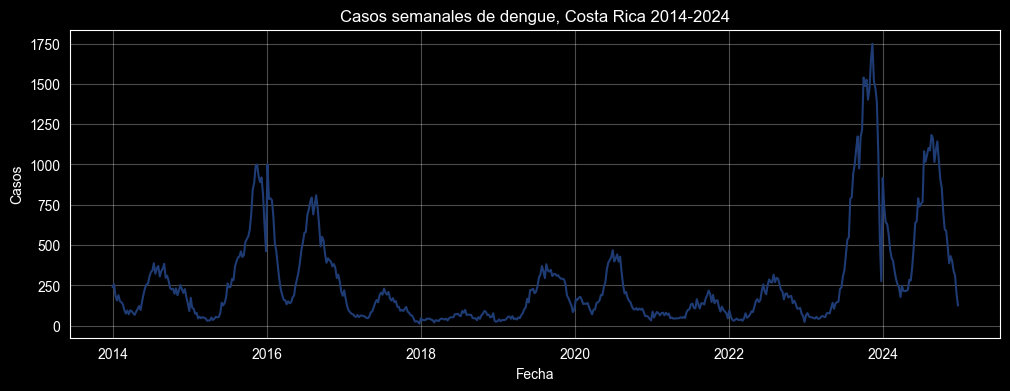

In [6]:
import matplotlib.pyplot as plt

# Gráfico de la serie semanal de casos de dengue (2014-2024)
plt.figure(figsize=(12, 4))
plt.plot(df["fecha_inicio_semana"], df["casos_dengue"], color="#1f3b73")
plt.title("Casos semanales de dengue, Costa Rica 2014-2024")
plt.xlabel("Fecha")
plt.ylabel("Casos")
plt.grid(alpha=0.3)
plt.show()

### Interpretación
- Los brotes más grandes son los de 2023 (máximo de casi 1750 casos en una semana) y 2024 (cerca de 1200). También hay un pico importante alrededor de 2016, de casi 1000 casos.
- Entre 2017 y 2019 y entre 2021 y 2022 los casos se mantienen bajos.
- La serie no sigue una tendencia fija: sube y baja en ciclos, con años de brote y años tranquilos.
- Durante el brote de 2023 hay una caída muy brusca y corta de los casos. Habría que revisar si es un cambio real o un problema en el registro de ese período.

## 4. Valores atípicos
Revisamos si hay valores muy fuera de lo normal en los casos y en la lluvia, y en qué fechas ocurrieron.

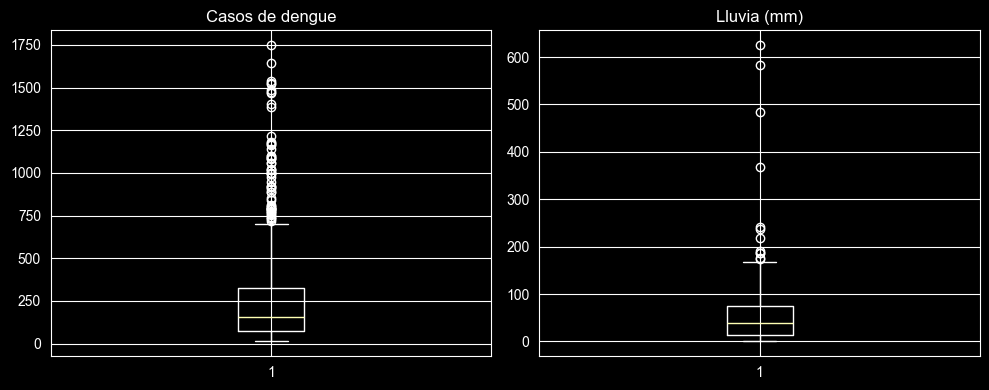

,fecha_inicio_semana,lluvia_mm,casos_dengue
543,2024-05-26,625.2,489
357,2020-11-01,583.6,106
567,2024-11-10,483.4,387
196,2017-10-01,368.0,98
544,2024-06-02,242.4,636


In [7]:
# Diagramas de caja para ver los valores atípicos de casos y lluvia
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

ejes[0].boxplot(df["casos_dengue"])
ejes[0].set_title("Casos de dengue")

ejes[1].boxplot(df["lluvia_mm"])
ejes[1].set_title("Lluvia (mm)")

plt.tight_layout()
plt.show()

# Las 5 semanas con más lluvia
df.nlargest(5, "lluvia_mm")[["fecha_inicio_semana", "lluvia_mm", "casos_dengue"]]

### Interpretación
- En los casos de dengue, los valores atípicos son las semanas de brote (más de unos 700 casos). Son datos reales de los brotes de 2016, 2023 y 2024, por eso no se eliminan.
- En la lluvia también hay valores atípicos. Las semanas más extremas fueron el 2024-05-26 (625.2 mm), el 2020-11-01 (583.6 mm), el 2024-11-10 (483.4 mm) y el 2017-10-01 (368 mm).
- Tres de esas semanas coinciden con eventos conocidos que indica el LEEME: Nate (oct. 2017), Eta (nov. 2020) y Sara (nov. 2024).
- Los casos de esas mismas semanas no fueron especialmente altos. Si la lluvia influye, el efecto debería verse semanas después, y eso lo revisamos más adelante con los rezagos.
- Decisión: dejamos todos los valores atípicos porque son eventos reales y el modelo debe aprender de ellos.

## 5. Estacionalidad
Revisamos si los casos de dengue y la lluvia cambian según el mes del año.

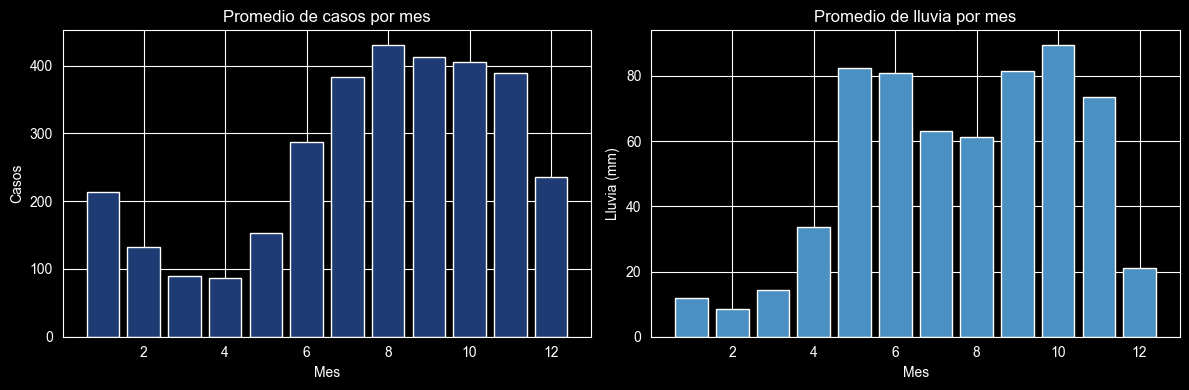

In [9]:
# Promedio de casos y de lluvia por mes del año
df["mes"] = df["fecha_inicio_semana"].dt.month
promedio_mensual = df.groupby("mes")[["casos_dengue", "lluvia_mm"]].mean()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].bar(promedio_mensual.index, promedio_mensual["casos_dengue"], color="#1f3b73")
ejes[0].set_title("Promedio de casos por mes")
ejes[0].set_xlabel("Mes")
ejes[0].set_ylabel("Casos")

ejes[1].bar(promedio_mensual.index, promedio_mensual["lluvia_mm"], color="#4a90c2")
ejes[1].set_title("Promedio de lluvia por mes")
ejes[1].set_xlabel("Mes")
ejes[1].set_ylabel("Lluvia (mm)")

plt.tight_layout()
plt.show()

### Interpretación
- Los casos de dengue tienen estacionalidad: son más bajos en marzo y abril (unos 90 casos promedio) y más altos en agosto (unos 430), manteniéndose altos hasta noviembre.
- La lluvia es muy baja de enero a marzo y sube fuerte desde mayo. El máximo promedio es en octubre.
- La lluvia sube en mayo y los casos suben después, entre junio y agosto. Esto sugiere que la lluvia no afecta los casos de inmediato, sino semanas más tarde. Lo vamos a comprobar con los rezagos.
- Estos promedios incluyen los años de brote (2016, 2023 y 2024), que pesan mucho. Sirven para ver el patrón general, pero no prueban por sí solos que la lluvia cause los casos.

## 6. Correlación y rezago entre clima y casos
Calculamos la correlación entre los casos de dengue (en logaritmo) y cada variable del clima de semanas anteriores (rezagos de 0 a 12 semanas), para ver con cuántas semanas de rezago la relación es más fuerte.

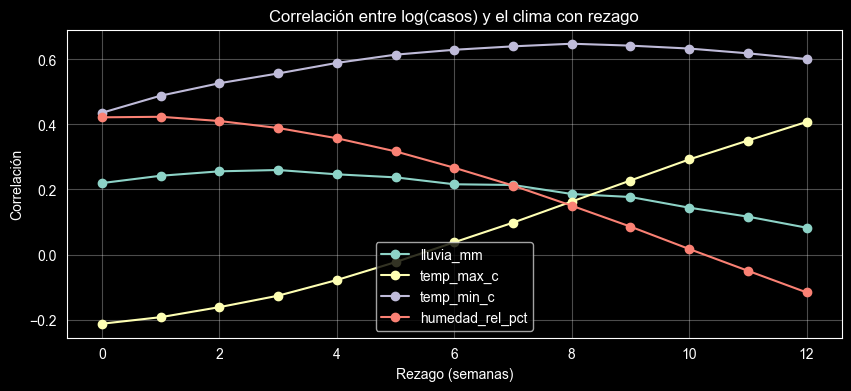

,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
rezago_semanas,,,,
0,0.22,-0.21,0.44,0.42
1,0.24,-0.19,0.49,0.42
2,0.26,-0.16,0.53,0.41
3,0.26,-0.13,0.56,0.39
4,0.25,-0.08,0.59,0.36
5,0.24,-0.02,0.61,0.32
6,0.22,0.04,0.63,0.27
7,0.21,0.10,0.64,0.21
8,0.19,0.16,0.65,0.15


In [10]:
import numpy as np

# Correlación entre log(casos) y el clima de k semanas antes (k de 0 a 12)
variables = ["lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
log_casos = np.log(df["casos_dengue"])

correlaciones = pd.DataFrame(
    {v: [log_casos.corr(df[v].shift(k)) for k in range(13)] for v in variables}
)
correlaciones.index.name = "rezago_semanas"

# Gráfico de las correlaciones según el rezago
correlaciones.plot(figsize=(10, 4), marker="o")
plt.title("Correlación entre log(casos) y el clima con rezago")
plt.xlabel("Rezago (semanas)")
plt.ylabel("Correlación")
plt.grid(alpha=0.3)
plt.show()

correlaciones.round(2)

### Interpretación
- La temperatura mínima es la variable que más se relaciona con los casos (en logaritmo). La correlación sube con el rezago: 0.44 sin rezago y 0.65 con 8 semanas. Entre 6 y 9 semanas casi no cambia, así que la mejor zona de rezago está entre 6 y 9 semanas.
- La lluvia tiene una relación débil con los casos: su máximo es 0.26, con 2 a 3 semanas de rezago.
- La humedad se relaciona más con los casos sin rezago (0.42) y pierde fuerza al aumentar el rezago.
- La temperatura máxima cambia de signo según el rezago (negativa con rezagos cortos y positiva con rezagos largos), por lo que es difícil de interpretar.
- El LEEME del profe reporta valores un poco distintos (r ≈ 0.71 con 6 semanas para la temperatura mínima y r ≈ 0.34 para la lluvia). La tendencia es la misma, pero no los números. No sabemos con qué método los calculó.
- La temperatura y los casos siguen ciclos anuales, así que una correlación alta no prueba que una cause la otra.
- Decisión para el modelo: crear variables con rezago de la temperatura mínima (alrededor de 6 a 9 semanas), de la lluvia (2 a 3 semanas) y de la humedad (0 a 2 semanas). La ventana de 26 semanas del LSTM cubre estos rezagos.